<a href="https://colab.research.google.com/github/novalrnv/PCVK_Ganjil_2026/blob/main/week-10/Modul10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 - Dasar-Dasar Deteksi Obyek

**Pengolahan Citra dan Visi Komputer - Modul 10**

| | |
|---|---|
| Nama | **Khoirul Umam Novalidi** |
| NIM | **244107020210** |
| Kelas | **TI-3C** |

## 0. Persiapan: Library dan Akses Drive

Import library yang dibutuhkan, mount Google Drive, lalu tentukan folder `Images`.
Kalau notebook dijalankan di luar Colab, folder `Images` diambil dari direktori kerja.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# import library yang dibutuhkan
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# akses drive
IN_COLAB = False
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/PCVK'
else:
    BASE_DIR = os.path.abspath('.')
    print('Bukan di Colab, folder kerja lokal dipakai:', BASE_DIR)

IMG_DIR  = os.path.join(BASE_DIR, 'Images')
FACEDET  = os.path.join(IMG_DIR, 'facedet')
CASCADE  = os.path.join(IMG_DIR, 'haarcascades')

print('Images      :', IMG_DIR)
print('facedet     :', FACEDET)
print('haarcascades:', CASCADE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images      : /content/drive/MyDrive/PCVK/Images
facedet     : /content/drive/MyDrive/PCVK/Images/facedet
haarcascades: /content/drive/MyDrive/PCVK/Images/haarcascades


### Helper

`path()` menyusun lokasi file, `display()` menampilkan citra tunggal, dan
`bandingkan()` menampilkan citra asli dan hasil berdampingan. `rgb()` dipakai karena
`cv.imread()` menghasilkan urutan warna BGR, sedangkan matplotlib memakai RGB.

In [3]:
def path(nama, sub=''):
    """Lokasi file di dalam folder Images (opsional: sub-folder)."""
    return os.path.join(IMG_DIR, sub, nama)


def rgb(img):
    """BGR -> RGB supaya warna tidak tertukar saat ditampilkan matplotlib."""
    return cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img


def display(img, judul=None, cmap=None, figsize=(12, 10)):
    if cmap is None and img.ndim == 2:
        cmap = 'gray'                    # citra grayscale ditampilkan abu-abu
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111)
    ax.imshow(rgb(img), cmap=cmap)
    if judul:
        ax.set_title(judul)
    ax.axis('off')
    plt.tight_layout()
    plt.show()


def bandingkan(asli, hasil, judul_asli='Citra Asli', judul_hasil='Hasil', figsize=(14, 6)):
    fig, ax = plt.subplots(1, 2, figsize=figsize)
    ax[0].imshow(rgb(asli), cmap='gray' if asli.ndim == 2 else None)
    ax[0].set_title(judul_asli)
    ax[0].axis('off')
    ax[1].imshow(rgb(hasil), cmap='gray' if hasil.ndim == 2 else None)
    ax[1].set_title(judul_hasil)
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

---
# D1. Praktikum Deteksi Obyek Dasar

## Soal 2 - Enam Metode Template Matching

`cv.matchTemplate()` menggeser template ke seluruh posisi pada citra sumber dan
menyimpan skor kecocokan pada matriks hasil `R`. Enam metode yang disediakan OpenCV
dibedakan dari cara menghitung skornya:

| Metode | Lokasi terbaik | Keterangan |
|---|---|---|
| `TM_SQDIFF`, `TM_SQDIFF_NORMED` | nilai **minimum** | selisih kuadrat antar piksel |
| `TM_CCORR`, `TM_CCORR_NORMED` | nilai **maksimum** | korelasi silang |
| `TM_CCOEFF`, `TM_CCOEFF_NORMED` | nilai **maksimum** | korelasi setelah citra dikurangi rata-ratanya |

Citra: `cats_and_bunnies.jpg` (source) dan `cat2_templatejpg.jpg` (template kucing).

ukuran source   : (829, 1024)
ukuran template : (449, 356)


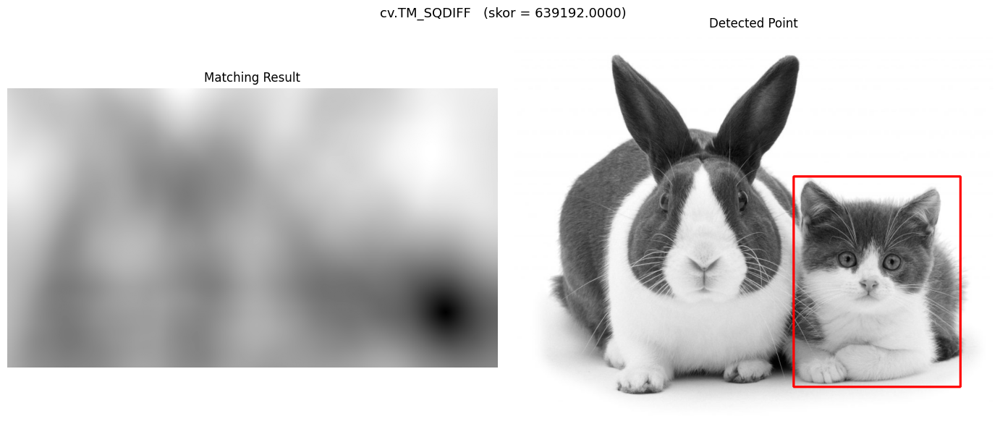

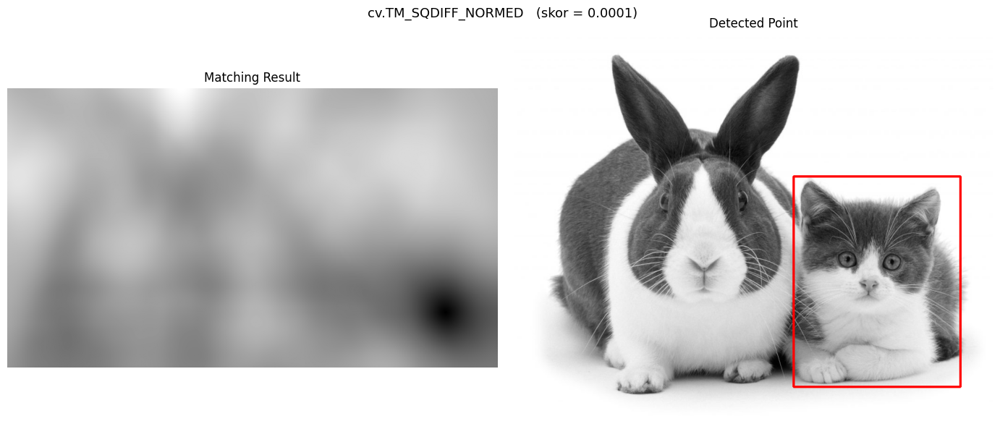

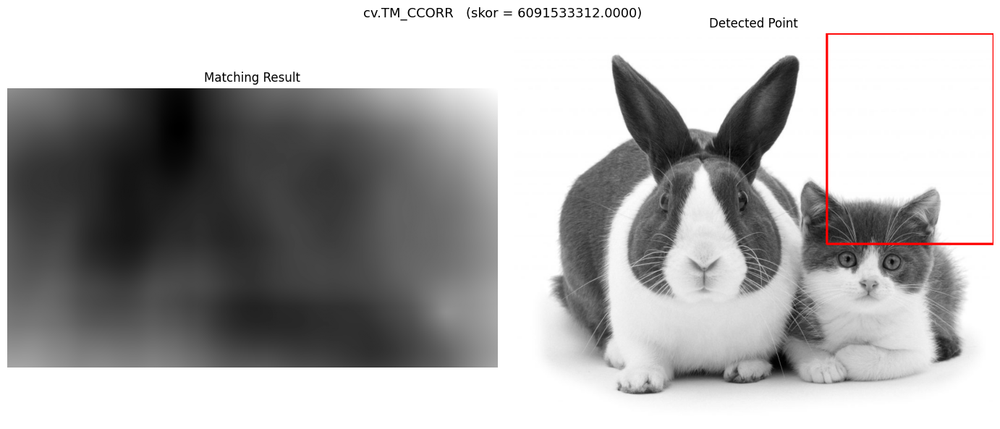

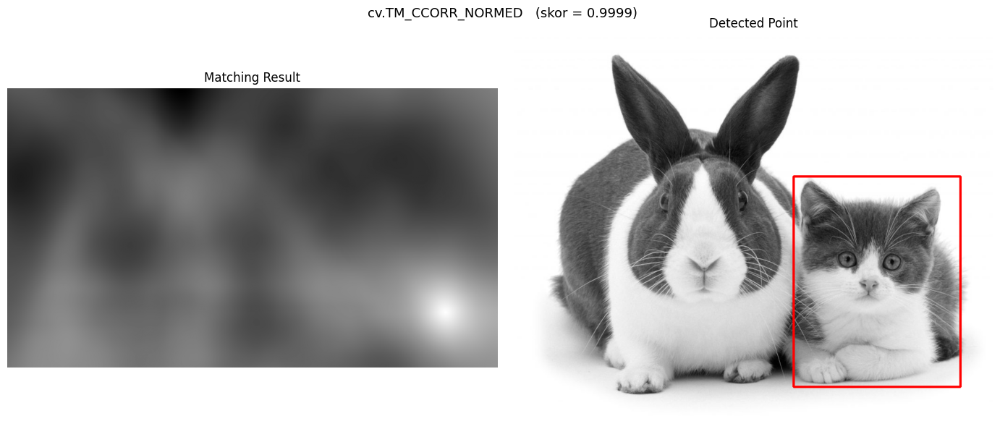

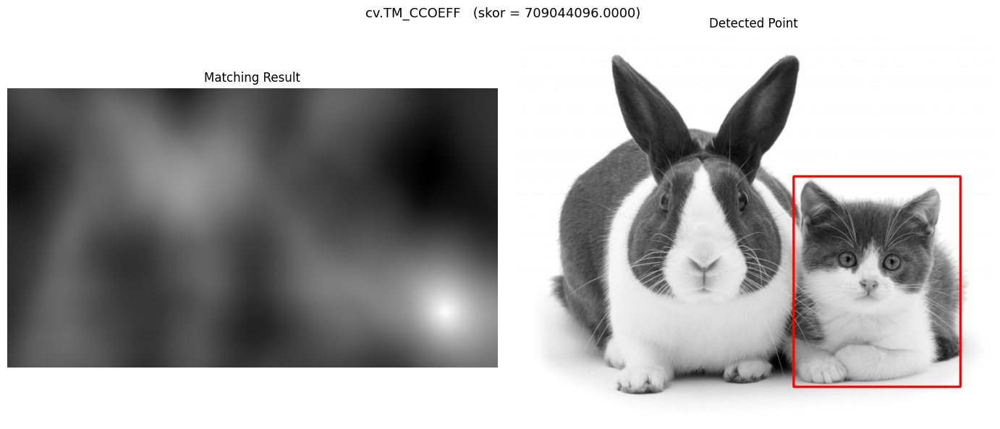

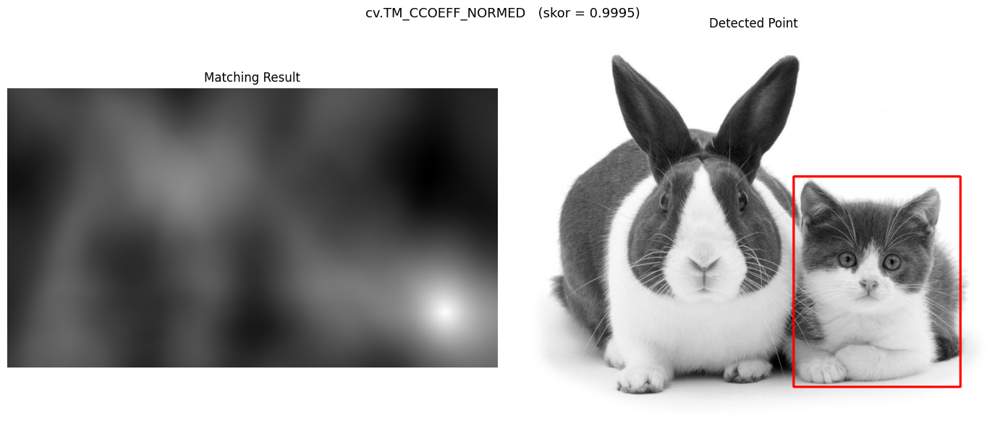

In [6]:
gambar   = cv.imread(path('cats_and_bunnies.jpg'), 0)   # source image (grayscale)
template = cv.imread(path('cat2_templatejpg.jpg'), 0)   # template image (grayscale)
h, w = template.shape

print('ukuran source   :', gambar.shape)
print('ukuran template :', template.shape)

daftar_metode = [
    ('cv.TM_SQDIFF',        cv.TM_SQDIFF),
    ('cv.TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('cv.TM_CCORR',         cv.TM_CCORR),
    ('cv.TM_CCORR_NORMED',  cv.TM_CCORR_NORMED),
    ('cv.TM_CCOEFF',        cv.TM_CCOEFF),
    ('cv.TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
]

# metode berbasis selisih: kecocokan terbaik ditandai nilai MINIMUM pada matriks R
metode_min = {cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED}

for nama, metode in daftar_metode:
    hasil = cv.matchTemplate(gambar, template, metode)          # matriks R
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(hasil)

    if metode in metode_min:
        kiri_atas, skor = min_loc, min_val
    else:
        kiri_atas, skor = max_loc, max_val
    kanan_bawah = (kiri_atas[0] + w, kiri_atas[1] + h)

    deteksi = cv.cvtColor(gambar, cv.COLOR_GRAY2BGR)
    cv.rectangle(deteksi, kiri_atas, kanan_bawah, (0, 0, 255), 3)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('{}   (skor = {:.4f})'.format(nama, skor), fontsize=13)
    ax[0].imshow(hasil, cmap='gray')
    ax[0].set_title('Matching Result')
    ax[0].axis('off')
    ax[1].imshow(rgb(deteksi))
    ax[1].set_title('Detected Point')
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

## Soal 3 - Template Matching Manual (Tanpa `cv.matchTemplate`)

Pada soal ini pencocokan dihitung sendiri dengan NumPy memakai **Normalized Cross
Correlation (NCC)**:

$$NCC(x,y)=\frac{\sum (I(x+i,\,y+j)-\bar{I})(T(i,j)-\bar{T})}{\sqrt{\sum (I(x+i,\,y+j)-\bar{I})^2 \cdot \sum (T(i,j)-\bar{T})^2}}$$

Nilai NCC berada di rentang -1 sampai 1; semakin dekat ke 1 semakin mirip. Karena
objeknya lebih dari satu (beberapa pulau buatan berbentuk huruf C pada `bahrain.jpg`),
setelah skor di-*threshold* masih perlu **Non-Maximum Suppression** agar satu objek
tidak menghasilkan banyak kotak yang bertumpuk.

Perhitungan dilakukan per potongan baris (`chunk`) supaya pemakaian memori tidak
meledak, karena jumlah jendela = (H-h+1) x (W-w+1) x h x w.

ukuran citra: (586, 596) | ukuran template: (73, 88)
kandidat di atas ambang : 332
setelah NMS             : 6


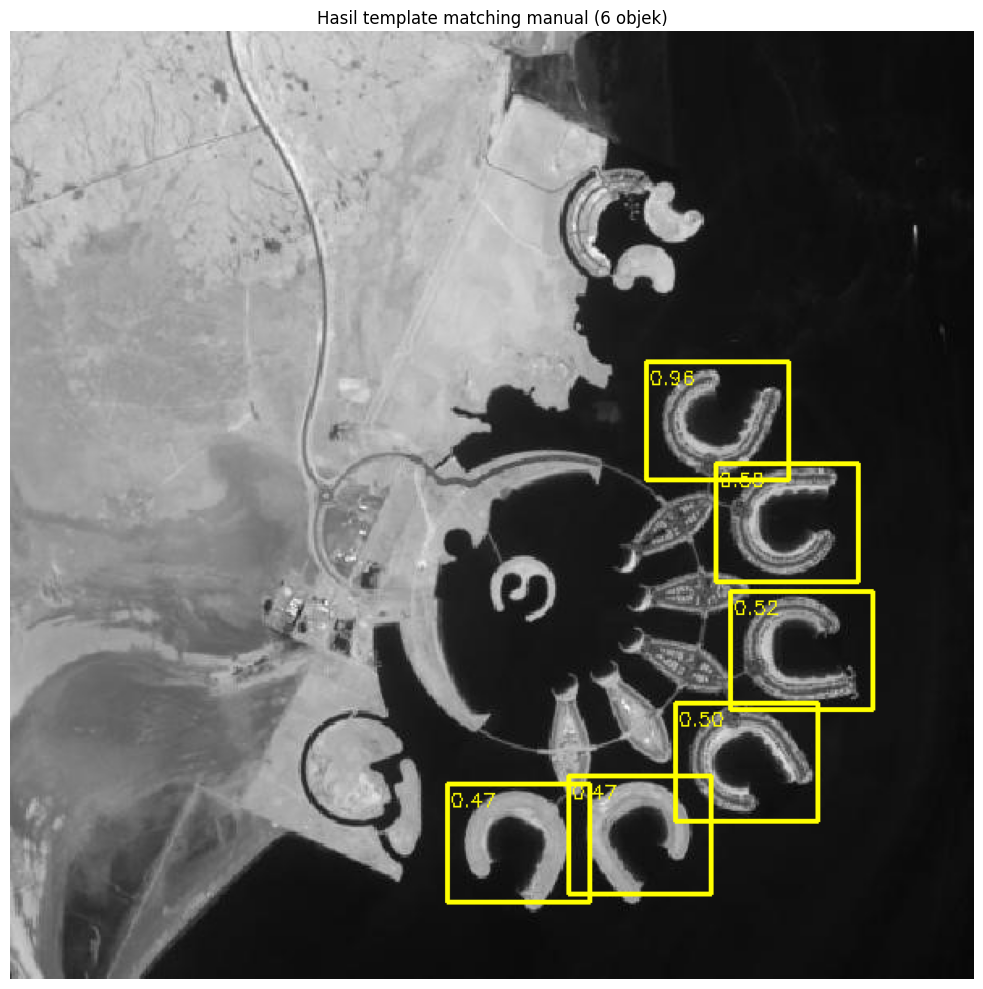

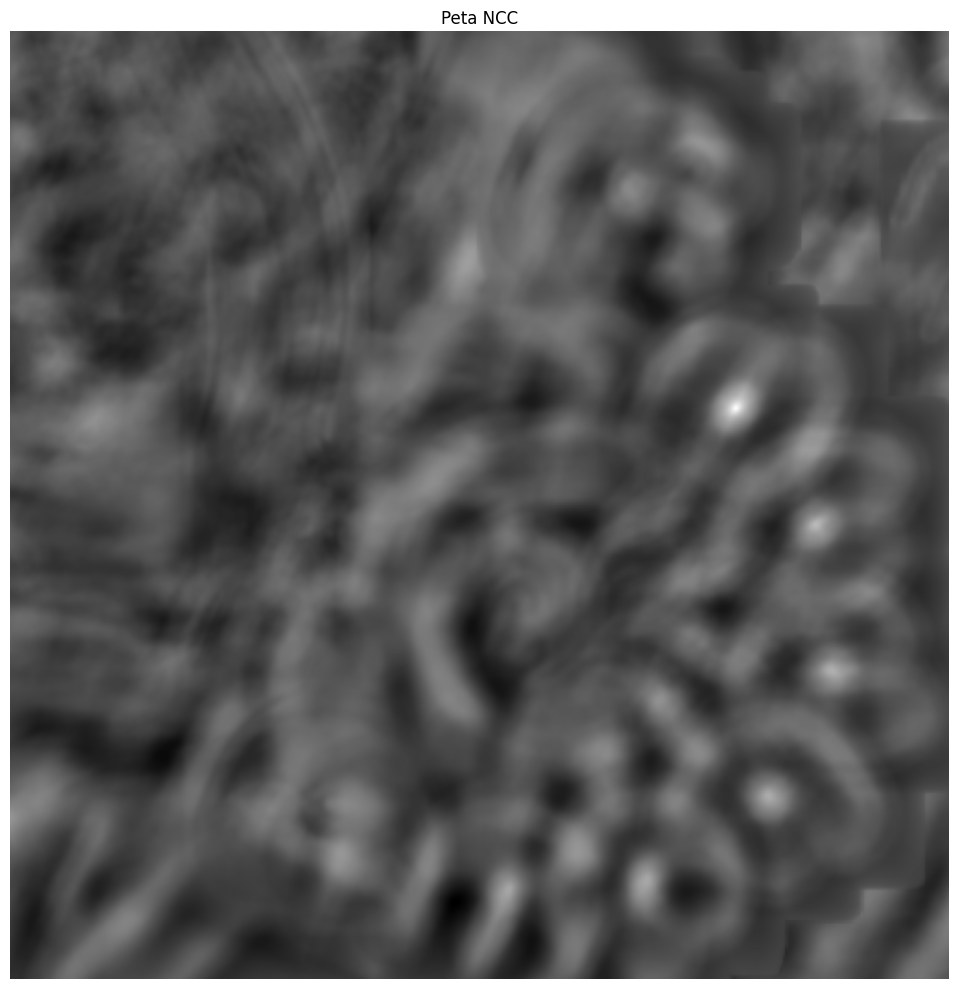

In [9]:
from numpy.lib.stride_tricks import sliding_window_view


def ncc_map(citra, templat, chunk=8):
    """Peta Normalized Cross Correlation, dihitung manual dengan NumPy."""
    H, W = citra.shape
    h, w = templat.shape

    citra_f = citra.astype(np.float32)
    t = templat.astype(np.float32)
    t = t - t.mean()                       # template dibuat zero-mean
    t_ss = float((t * t).sum())

    jendela = sliding_window_view(citra_f, (h, w))      # (H-h+1, W-w+1, h, w)
    peta = np.zeros((H - h + 1, W - w + 1), np.float32)

    for y in range(0, peta.shape[0], chunk):
        blok = jendela[y:y + chunk]
        rata = blok.mean(axis=(2, 3), keepdims=True)
        selisih = blok - rata
        pembilang = (selisih * t).sum(axis=(2, 3))
        penyebut = np.sqrt((selisih ** 2).sum(axis=(2, 3)) * t_ss) + 1e-6
        peta[y:y + chunk] = pembilang / penyebut

    return peta


def iou(a, b):
    """Intersection over Union dua kotak (x1, y1, x2, y2, skor)."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def nms(kotak, ambang_iou=0.3):
    """Non-Maximum Suppression: buang kotak yang tumpang tindih dengan kotak terbaik."""
    kotak = sorted(kotak, key=lambda b: b[4], reverse=True)
    terpilih = []
    for b in kotak:
        if all(iou(b, s) < ambang_iou for s in terpilih):
            terpilih.append(b)
    return terpilih


citra    = cv.imread(path('bahrain.jpg'), 0)
templat  = cv.imread(path('bahrain-template.jpg'), 0)
h, w = templat.shape
print('ukuran citra:', citra.shape, '| ukuran template:', templat.shape)

peta = ncc_map(citra, templat)

AMBANG = 0.45          # turunkan bila ada objek yang terlewat, naikkan bila terlalu banyak kotak salah
ys, xs = np.where(peta >= AMBANG)
kotak = [(x, y, x + w, y + h, float(peta[y, x])) for y, x in zip(ys, xs)]
terpilih = nms(kotak, 0.3)

print('kandidat di atas ambang :', len(kotak))
print('setelah NMS             :', len(terpilih))

deteksi = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)
for x1, y1, x2, y2, skor in terpilih:
    cv.rectangle(deteksi, (x1, y1), (x2, y2), (0, 255, 255), 2)
    cv.putText(deteksi, '{:.2f}'.format(skor), (x1 + 2, y1 + 14),
               cv.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)

display(deteksi, judul='Hasil template matching manual ({} objek)'.format(len(terpilih)))
display(peta, cmap='gray', judul='Peta NCC')

## Soal 4 - Edge Detection (Sobel, Canny, Laplacian)

Citra: `car-park.jpg`.

- **Sobel**: menghitung gradien intensitas arah X (vertikal) dan Y (horizontal) dengan
  kernel 3x3, lalu digabung menjadi magnitudo gradien.
- **Laplacian**: turunan kedua, sangat sensitif terhadap noise sehingga citra
  dihaluskan dulu dengan Gaussian filter.
- **Canny**: Gaussian -> gradien Sobel -> non-maximum suppression -> hysteresis threshold.

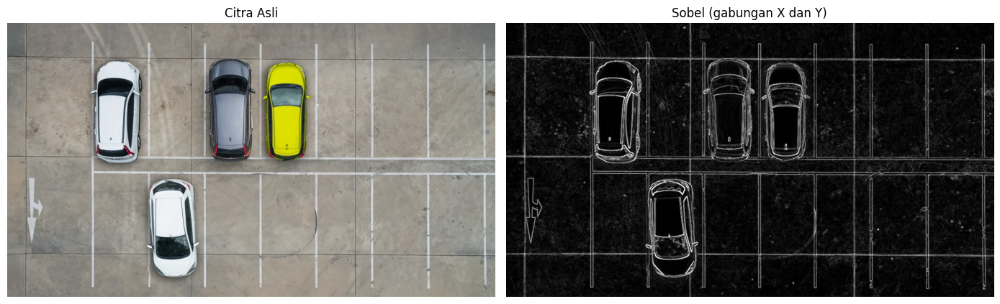

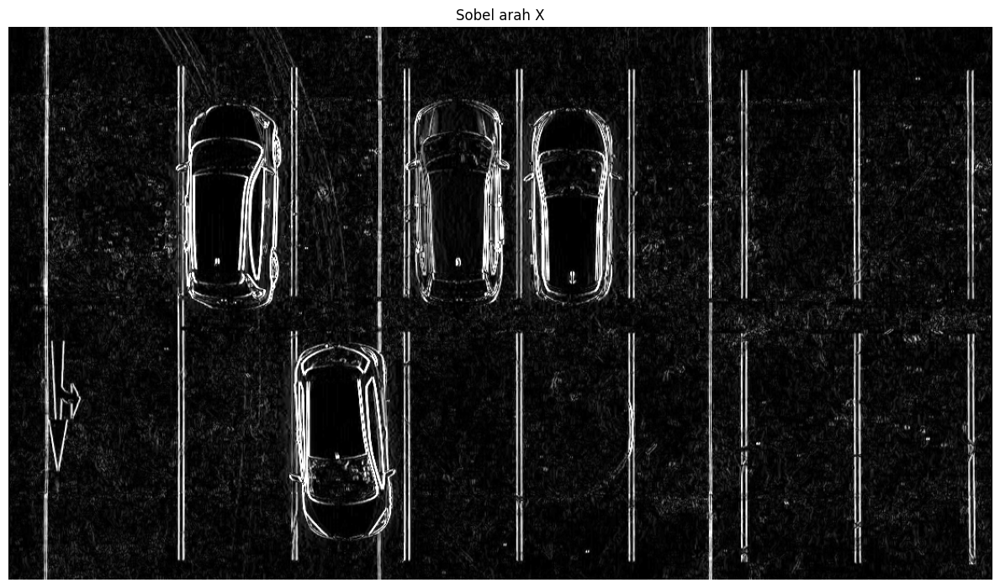

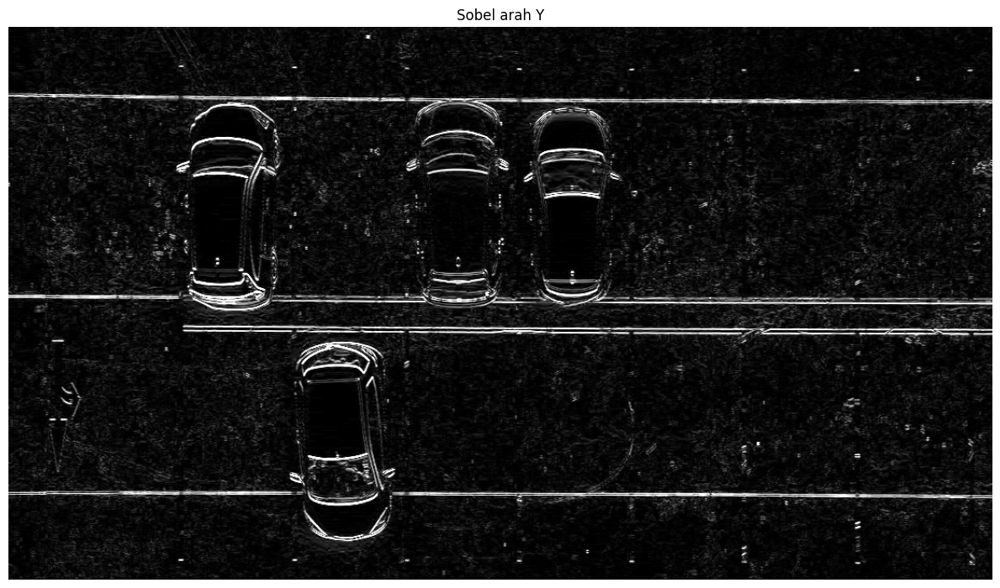

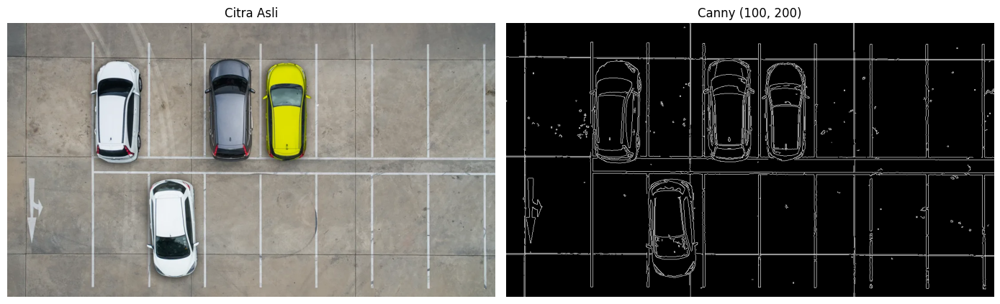

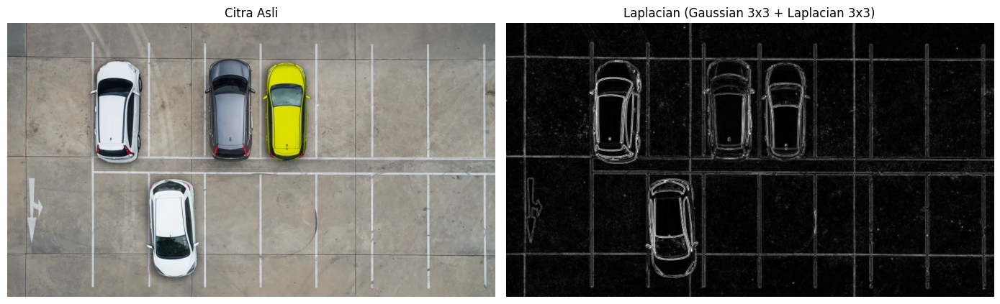

In [10]:
img  = cv.imread(path('car-park.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
gx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)     # gradien arah X
gy = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)     # gradien arah Y
abs_gx = cv.convertScaleAbs(gx)
abs_gy = cv.convertScaleAbs(gy)
sobel = cv.addWeighted(abs_gx, 0.5, abs_gy, 0.5, 0)

# b. Canny Edge Detection
canny = cv.Canny(gray, 100, 200)

# c. Laplacian Edge Detection (dihaluskan dulu dengan Gaussian)
blur = cv.GaussianBlur(gray, (3, 3), 0)
laplacian = cv.convertScaleAbs(cv.Laplacian(blur, cv.CV_16S, ksize=3))

bandingkan(img, sobel, 'Citra Asli', 'Sobel (gabungan X dan Y)')
display(abs_gx, judul='Sobel arah X')
display(abs_gy, judul='Sobel arah Y')
bandingkan(img, canny, 'Citra Asli', 'Canny (100, 200)')
bandingkan(img, laplacian, 'Citra Asli', 'Laplacian (Gaussian 3x3 + Laplacian 3x3)')

## Soal 5 - Corner Detection (Harris dan Shi-Tomasi)

Citra: `chess-board.jpg`.

- **Harris**: menilai sebuah titik dari nilai $R = \det(M) - k\,(\text{trace}(M))^2$.
  Titik dianggap sudut jika $R$ besar.
- **Shi-Tomasi**: menyederhanakan penilaian menjadi $R = \min(\lambda_1, \lambda_2)$,
  lalu mengambil N sudut terkuat lewat `cv.goodFeaturesToTrack()`.

jumlah sudut Shi-Tomasi: 100
jumlah piksel sudut Harris:  2238


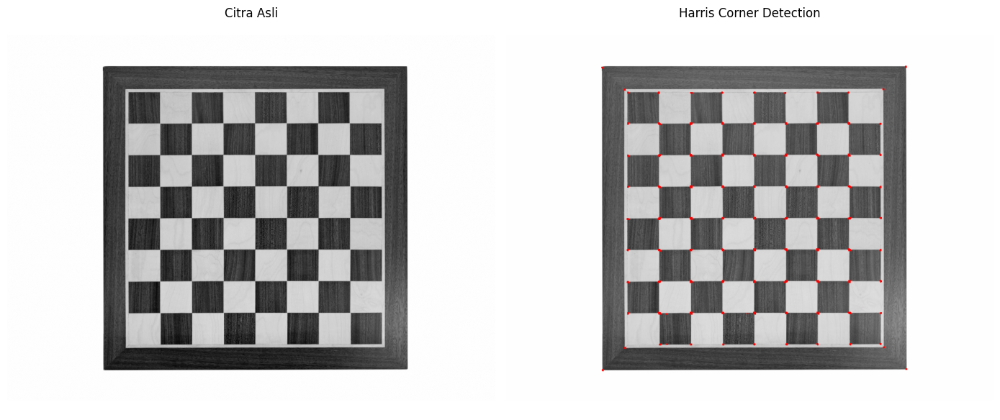

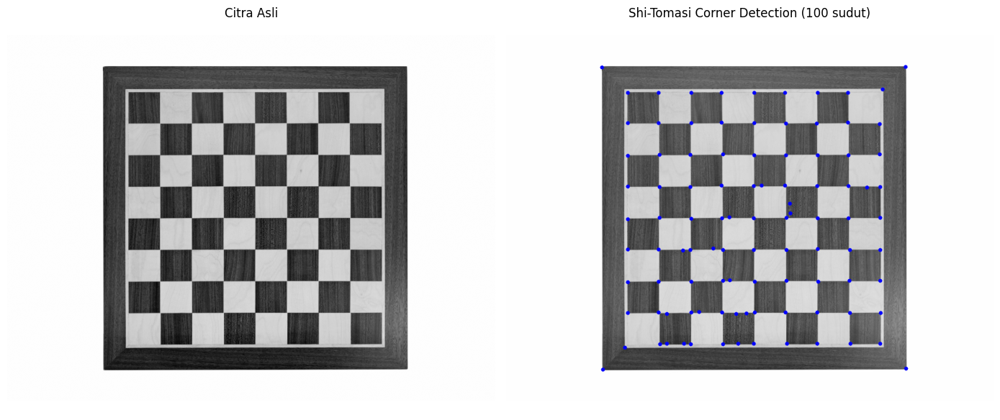

In [11]:
gray = cv.imread(path('chess-board.jpg'), 0)

# a. Harris Corner Detection
gray_f = np.float32(gray)
R = cv.cornerHarris(gray_f, blockSize=2, ksize=3, k=0.04)
R = cv.dilate(R, None)          # mempertebal titik sudut agar terlihat
harris = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
harris[R > 0.01 * R.max()] = (0, 0, 255)     # titik sudut diberi warna merah

# b. Shi-Tomasi Corner Detection
sudut = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
shi = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for s in sudut:
    x, y = np.ravel(s)
    cv.circle(shi, (int(x), int(y)), 4, (255, 0, 0), -1)

print('jumlah sudut Shi-Tomasi:', len(sudut))
print('jumlah piksel sudut Harris: ', int((R > 0.01 * R.max()).sum()))

bandingkan(gray, harris, 'Citra Asli', 'Harris Corner Detection')
bandingkan(gray, shi, 'Citra Asli', 'Shi-Tomasi Corner Detection (100 sudut)')

## Soal 6 - Grid Detection dengan Hough Transform

Citra: `sudoku.jpg`. Tahapan sesuai modul:

1. Canny edge detection
2. Dilasi (menggabungkan dua tepi tipis yang berdekatan menjadi satu)
3. Erosi (menipiskan kembali agar Hough tidak mendeteksi garis ganda)
4. `cv.HoughLines()`
5. Menggabungkan garis yang mirip (jarak `rho` dan sudut `theta` berdekatan)

garis terdeteksi: 54
garis setelah digabung: 25


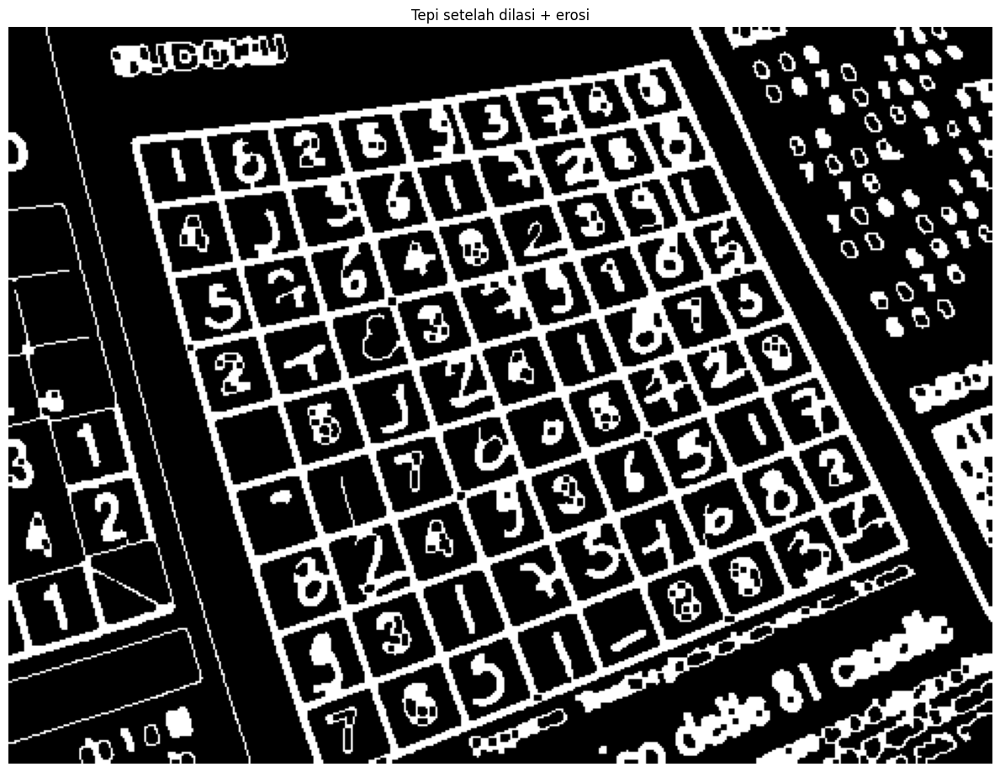

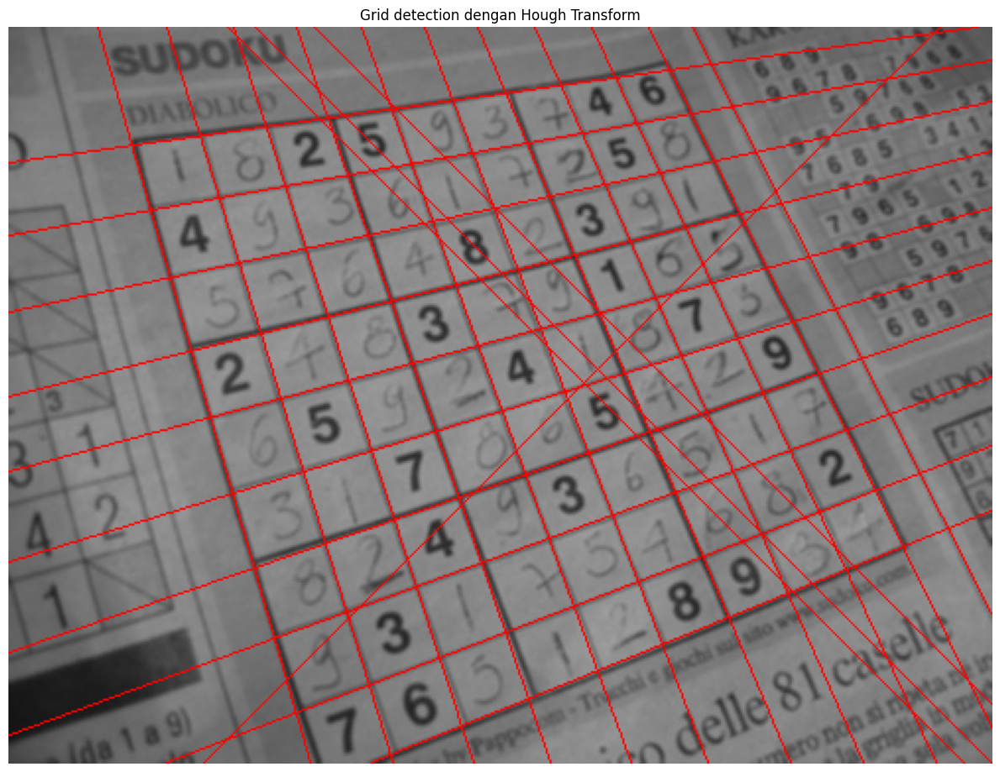

In [12]:
img  = cv.imread(path('sudoku.jpg'), 0)

# 1. Canny
edges = cv.Canny(img, 50, 150, apertureSize=3)

# 2. dilasi + 3. erosi
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(edges, kernel, iterations=1)
erosi = cv.erode(dilasi, kernel, iterations=1)

# 4. Hough Transform (mendeteksi garis lurus)
#    threshold tinggi dipakai agar baris angka tidak ikut terdeteksi sebagai garis
garis = cv.HoughLines(erosi, 1, np.pi / 180, threshold=250)
print('garis terdeteksi:', 0 if garis is None else len(garis))

# 5. gabungkan garis yang mirip (rho selisih < 10 px dan theta selisih < 2 derajat)
garis_unik = []
for rho, theta in (garis[:, 0] if garis is not None else []):
    mirip = any(abs(rho - r) < 10 and abs(theta - t) < np.deg2rad(2) for r, t in garis_unik)
    if not mirip:
        garis_unik.append((rho, theta))
print('garis setelah digabung:', len(garis_unik))

hasil = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
for rho, theta in garis_unik:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
    p2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
    cv.line(hasil, p1, p2, (0, 0, 255), 1)

display(erosi, judul='Tepi setelah dilasi + erosi')
display(hasil, judul='Grid detection dengan Hough Transform')

## Soal 7 - Contour Detection

Citra: `laptop.jpg`. Kontur adalah kurva tertutup yang menghubungkan titik-titik
dengan intensitas sama, sehingga mewakili bentuk objek. Tahapannya: citra dibuat
biner (Canny), kontur dicari dengan `findContours()`, lalu digambar dengan
`drawContours()`.

Citra ini berukuran besar (3840x2560), jadi diperkecil dulu supaya lebih cepat dan
gambar tetap muat di layar.

jumlah kontur: 111
kontur dengan luas > 2000 px: 10


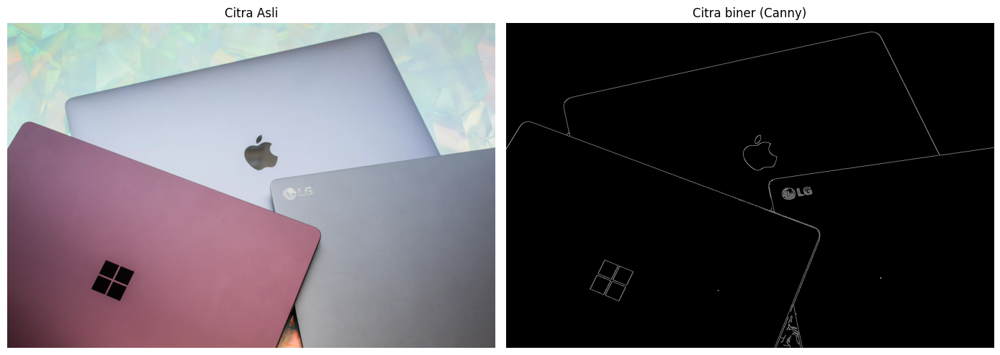

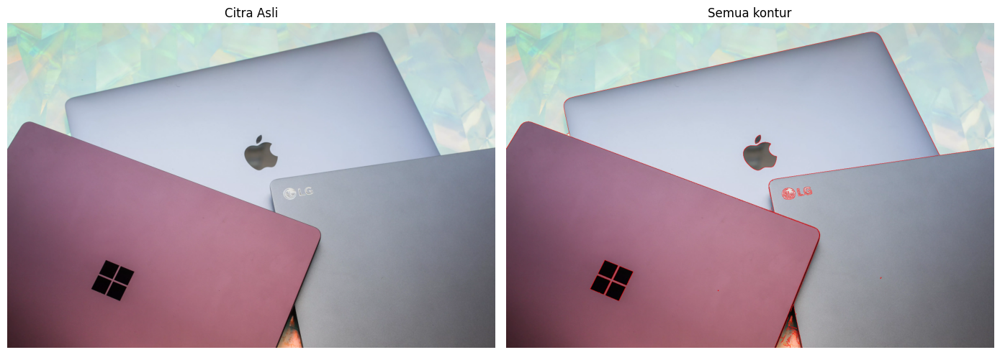

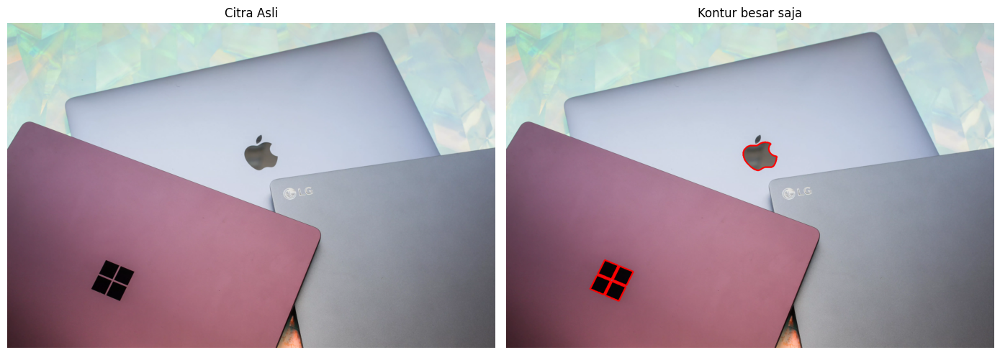

In [13]:
img = cv.imread(path('laptop.jpg'))
img = cv.resize(img, None, fx=0.4, fy=0.4, interpolation=cv.INTER_AREA)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. citra biner
biner = cv.Canny(gray, 50, 150)

# 2. cari kontur
kontur, hierarki = cv.findContours(biner, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)

# 3. gambar kontur
hasil = img.copy()
cv.drawContours(hasil, kontur, -1, (0, 0, 255), 1)
print('jumlah kontur:', len(kontur))

# kontur yang cukup besar saja (menyaring noise)
besar = [k for k in kontur if cv.contourArea(k) > 2000]
hasil_besar = img.copy()
cv.drawContours(hasil_besar, besar, -1, (0, 0, 255), 3)
print('kontur dengan luas > 2000 px:', len(besar))

bandingkan(img, biner, 'Citra Asli', 'Citra biner (Canny)')
bandingkan(img, hasil, 'Citra Asli', 'Semua kontur')
bandingkan(img, hasil_besar, 'Citra Asli', 'Kontur besar saja')

---
# D2. Praktikum Feature Matching dan Face Detection


## Soal 8 - Face Detection dengan Haar Cascade

Haar Cascade (Viola-Jones) bekerja dengan menggeser jendela fitur (edge, line,
rectangle) pada *integral image*, lalu menyaringnya secara bertahap dengan cascade
classifier. Pencarian dilakukan pada citra **grayscale**.

`detectMultiScale()` mengembalikan daftar kotak `(x, y, w, h)` untuk setiap wajah.
Parameter yang dipakai:
- `scaleFactor=1.1` - gambar diperkecil 10% tiap iterasi pencarian,
- `minNeighbors=5` - minimal 5 kotak bertetangga harus sepakat ada wajah (mengurangi
  deteksi palsu).

Pretrained feature: `haarcascade_frontalface_alt.xml`.

cascade berhasil dimuat: True
jokowi.jpg -> 1 wajah [(290, 150, 363, 363)]
kartini.jpg -> 1 wajah [(185, 125, 224, 224)]
mjordan.jpg -> 1 wajah [(42, 80, 229, 229)]
solvayconf.jpg -> 27 wajah [(854, 261, 38, 38), (237, 290, 36, 36), (722, 295, 41, 41), (800, 296, 31, 31), (900, 292, 40, 40), (554, 298, 33, 33), (378, 307, 36, 36), (638, 296, 42, 42), (290, 312, 37, 37), (490, 358, 38, 38), (45, 360, 38, 38), (893, 371, 45, 45), (245, 362, 42, 42), (788, 366, 46, 46), (140, 376, 40, 40), (581, 361, 38, 38), (359, 360, 46, 46), (674, 364, 44, 44), (732, 392, 45, 45), (80, 398, 38, 38), (934, 415, 41, 41), (296, 399, 40, 40), (408, 398, 49, 49), (850, 398, 47, 47), (643, 394, 44, 44), (550, 393, 44, 44), (184, 400, 46, 46)]
mask.png -> 5 wajah [(63, 64, 115, 115), (306, 64, 116, 116), (65, 304, 112, 112), (306, 300, 117, 117), (546, 299, 120, 120)]


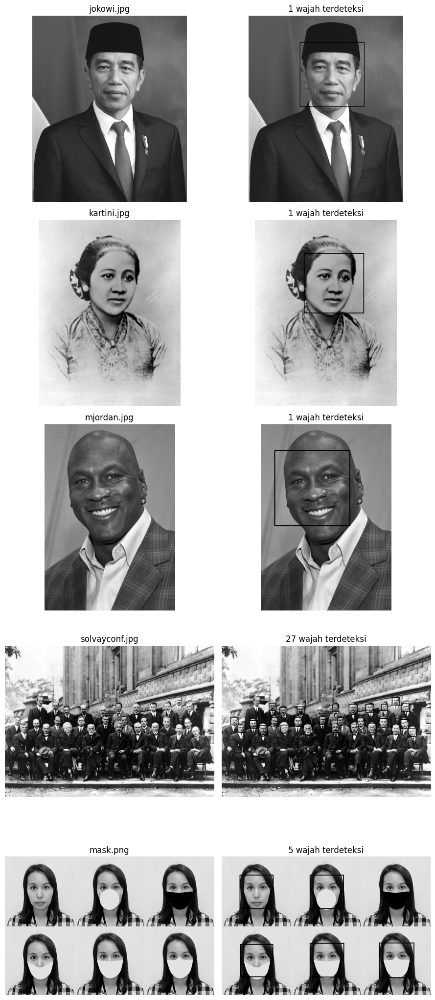

In [20]:
cascade_wajah = cv.CascadeClassifier(path('haarcascade_frontalface_alt.xml', 'haarcascades'))
print('cascade berhasil dimuat:', not cascade_wajah.empty())

daftar = ['jokowi.jpg', 'kartini.jpg', 'mjordan.jpg', 'solvayconf.jpg', 'mask.png']

fig, ax = plt.subplots(len(daftar), 2, figsize=(9, 4.2 * len(daftar)))
for baris, nama in enumerate(daftar):
    img = cv.imread(path(nama, 'facedet'))
    abu = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    roi_wajah = cascade_wajah.detectMultiScale(abu, scaleFactor=1.1, minNeighbors=5)

    hasil = abu.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

    ax[baris, 0].imshow(abu, cmap='gray')
    ax[baris, 0].set_title(nama)
    ax[baris, 0].axis('off')
    ax[baris, 1].imshow(hasil, cmap='gray')
    ax[baris, 1].set_title('{} wajah terdeteksi'.format(len(roi_wajah)))
    ax[baris, 1].axis('off')

    # modul menampilkan mask.png dalam bentuk grid wajah, jadi tiap wajah dicetak juga
    print(nama, '->', len(roi_wajah), 'wajah', [tuple(map(int, r)) for r in roi_wajah])

plt.tight_layout()
plt.show()

## Soal 9 - Deteksi Wajah Kucing

Wajah kucing tidak terdeteksi oleh `haarcascade_frontalface_alt.xml` karena bentuk
fitur wajahnya berbeda dari manusia. OpenCV menyediakan cascade khusus kucing:
`haarcascade_frontalcatface_extended.xml`.

Kunci agar berhasil: `scaleFactor` dibuat kecil (1.05) supaya pencarian lebih rapat.

Cascade kucing biasanya mengembalikan **dua kotak bersarang**: satu kotak wajah dan satu
kotak kecil di hidung. Karena itu sel di bawah hanya mengambil kotak dengan luas
terbesar.

cascade berhasil dimuat: True
frontalface_alt   : 0 wajah
frontalcatface    : 1 wajah kucing


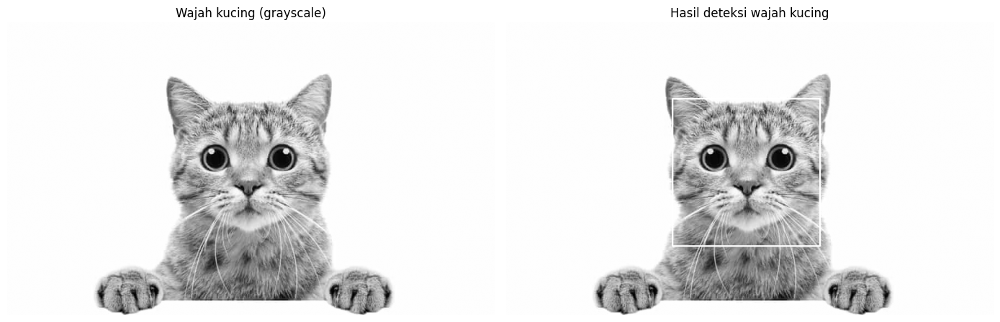

In [23]:
cascade_kucing = cv.CascadeClassifier(path('haarcascade_frontalcatface_extended.xml', 'haarcascades'))
print('cascade berhasil dimuat:', not cascade_kucing.empty())

kucing = cv.imread(path('kucing.jpg', 'facedet'))
abu = cv.cvtColor(kucing, cv.COLOR_BGR2GRAY)

# sebagai pembanding: cascade wajah manusia (gagal mendeteksi)
gagal = cascade_wajah.detectMultiScale(abu, scaleFactor=1.1, minNeighbors=5)
print('frontalface_alt   :', len(gagal), 'wajah')

roi_kucing = cascade_kucing.detectMultiScale(abu, scaleFactor=1.05, minNeighbors=5)

# cascade kucing sering menghasilkan kotak bersarang (wajah + hidung),
# jadi diambil kotak terbesar saja karena kotak itulah yang mencakup wajah
if len(roi_kucing) > 0:
    roi_kucing = [max(roi_kucing, key=lambda r: r[2] * r[3])]
print('frontalcatface    :', len(roi_kucing), 'wajah kucing')

hasil = abu.copy()
for (x, y, w, h) in roi_kucing:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 255, 255), 2)

bandingkan(abu, hasil, 'Wajah kucing (grayscale)', 'Hasil deteksi wajah kucing')

## Soal 10 - Eyes Detection pada Wajah Pak Prabowo

Deteksi mata dilakukan **di dalam** kotak wajah (region of interest), bukan pada
seluruh citra. Caranya: cari wajah dulu, potong ROI-nya, lalu jalankan
`haarcascade_eye.xml` pada potongan tersebut. Koordinat mata yang dihasilkan masih
relatif terhadap ROI, sehingga saat menggambar harus ditambah offset `(x, y)` wajah.

`minNeighbors` dan `scaleFactor` di sel ini perlu diatur cukup longgar, karena
`haarcascade_eye.xml` mudah salah menandai alis atau bagian hidung sebagai mata.

mata terdeteksi: 2


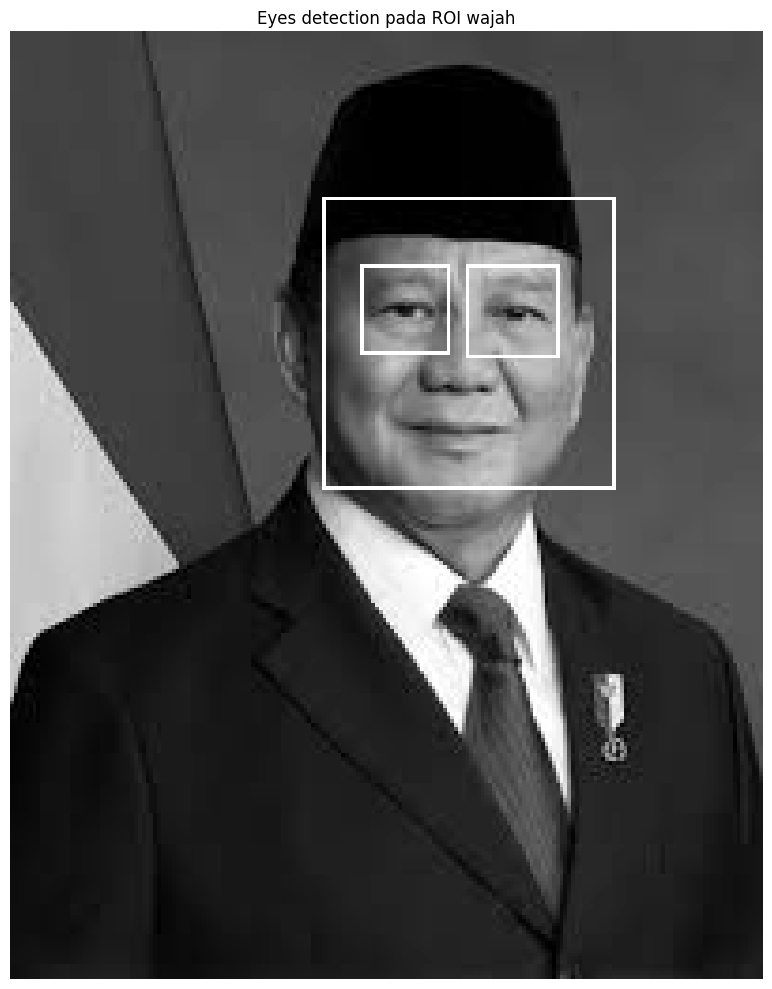

In [26]:
cascade_mata = cv.CascadeClassifier(path('haarcascade_eye.xml', 'haarcascades'))

prabowo = cv.imread(path('prabowo.jpg'), 0)          # dibaca grayscale
roi_wajah = cascade_wajah.detectMultiScale(prabowo, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in roi_wajah:
    cv.rectangle(prabowo, (x, y), (x + w, y + h), (255, 255, 255), 1)

    roi_abu = prabowo[y:y + h, x:x + w]                       # ROI wajah
    roi_mata = cascade_mata.detectMultiScale(roi_abu, scaleFactor=1.05, minNeighbors=5)
    for (ex, ey, ew, eh) in roi_mata:
        cv.rectangle(roi_abu, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 1)
    print('mata terdeteksi:', len(roi_mata))

display(prabowo, judul='Eyes detection pada ROI wajah')

## Soal 11 - Deteksi Senyuman pada Gambar `mjordan.jpg`

Pencarian senyum (mulut) juga dibatasi pada ROI wajah dan hanya pada **bagian bawah**
ROI, karena bibir selalu berada di bawah mata. Tanpa pembatasan itu, cascade senyum
sering salah menandai mata atau hidung.

Parameter yang dipakai `scaleFactor=1.7` dan `minNeighbors=15`. Nilai `minNeighbors`
boleh dinaikkan bila terlalu banyak kotak palsu, atau diturunkan bila ada senyum yang
tidak terdeteksi.

file: /content/drive/MyDrive/PCVK/Images/facedet/mjordan.jpg | ada: True
jumlah wajah: 1


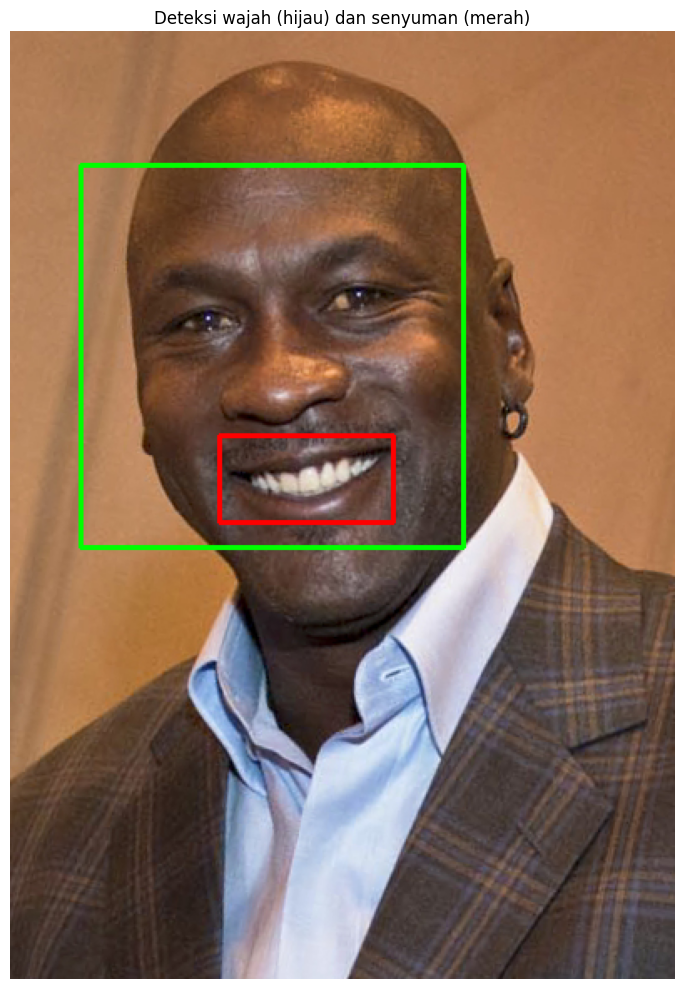

In [25]:
cascade_senyum = cv.CascadeClassifier(path('haarcascade_smile.xml', 'haarcascades'))

BERKAS_PEOPLE = path('mjordan.jpg', 'facedet')
print('file:', BERKAS_PEOPLE, '| ada:', os.path.exists(BERKAS_PEOPLE))

if os.path.exists(BERKAS_PEOPLE):
    people = cv.imread(BERKAS_PEOPLE)
    abu = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
    roi_wajah = cascade_wajah.detectMultiScale(abu, scaleFactor=1.1, minNeighbors=5)
    print('jumlah wajah:', len(roi_wajah))

    for (x, y, w, h) in roi_wajah:
        cv.rectangle(people, (x, y), (x + w, y + h), (0, 255, 0), 2)

        # bagian bawah wajah saja
        roi_bawah = abu[y + h // 2:y + h, x:x + w]
        roi_senyum = cascade_senyum.detectMultiScale(roi_bawah, scaleFactor=1.7, minNeighbors=15)
        for (sx, sy, sw, sh) in roi_senyum:
            cv.rectangle(people, (x + sx, y + h // 2 + sy),
                         (x + sx + sw, y + h // 2 + sy + sh), (0, 0, 255), 2)

    display(people, judul='Deteksi wajah (hijau) dan senyuman (merah)')
else:
    print('Letakkan gambar people.jpg di', BERKAS_PEOPLE, 'lalu jalankan ulang sel ini.')

## Soal 12 - Face Tracking dengan Google Colab

Google Colab tidak bisa membuka kamera laptop secara langsung dari Python. Solusinya
adalah memakai JavaScript di browser: snippet *Camera capture* (menu kiri Colab ->
*Code snippets*) menangkap frame kamera, mengubahnya menjadi string base64, lalu
dikirim ke Python untuk diproses dan dikembalikan sebagai gambar.

Sel di bawah menjalankan dua potong kode: (1) JavaScript untuk membuka kamera, dan
(2) loop Python yang membaca 10 frame, mendeteksi wajah, lalu menampilkannya kembali.

> Sel ini hanya jalan di Google Colab dengan kamera yang diizinkan. Kalau dijalankan
> di luar Colab (atau kamera diblokir), sel akan berhenti dengan pesan, bukan error.

<IPython.core.display.Javascript object>

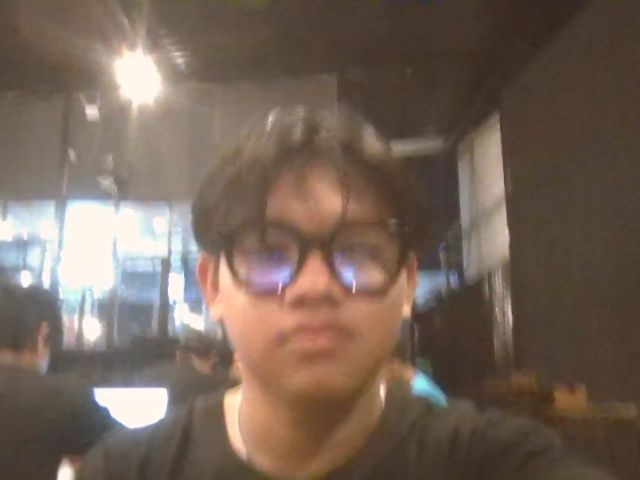

frame 1 -> 0 wajah


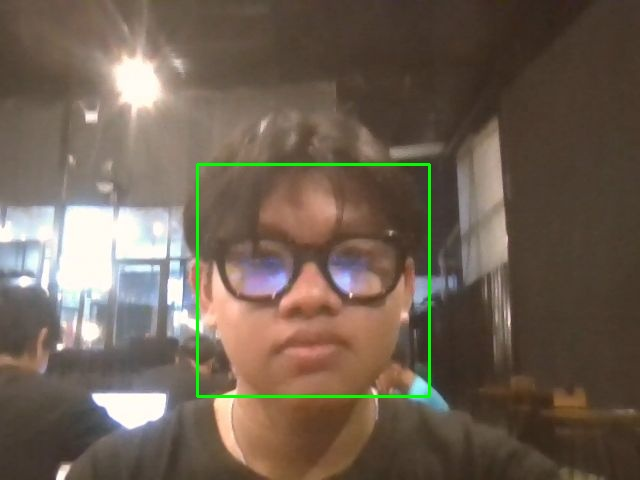

frame 2 -> 1 wajah


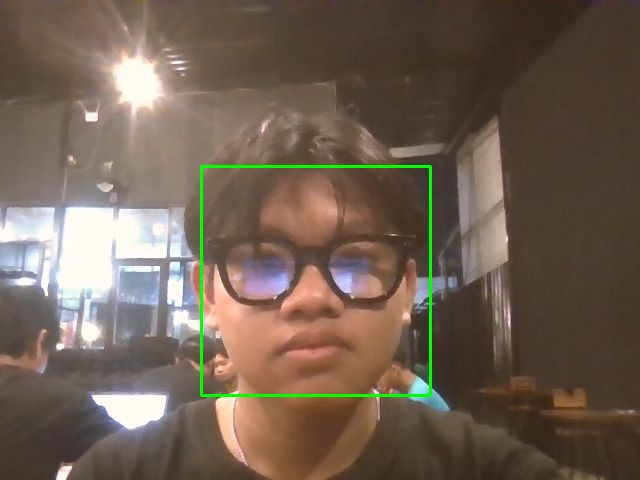

frame 3 -> 1 wajah


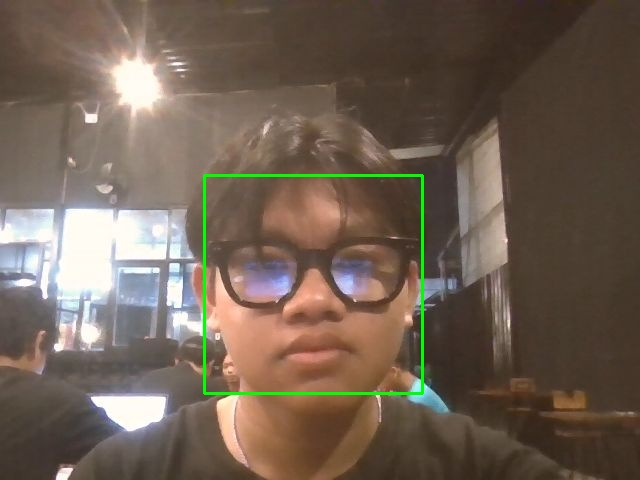

frame 4 -> 1 wajah


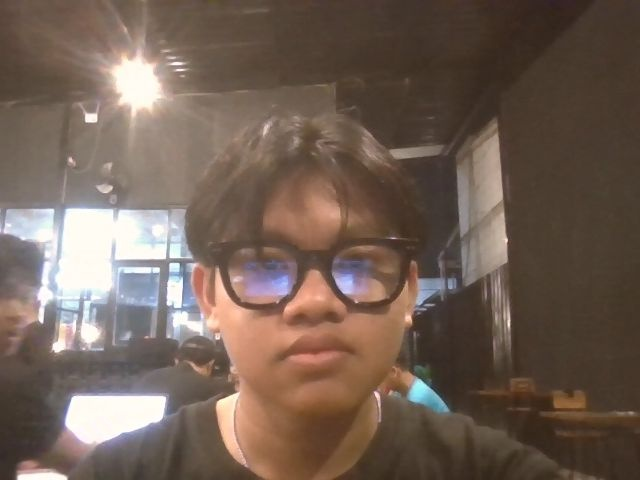

frame 5 -> 0 wajah


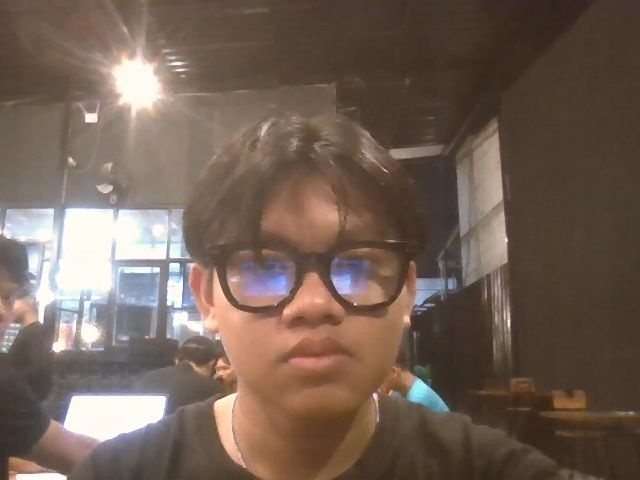

frame 6 -> 0 wajah


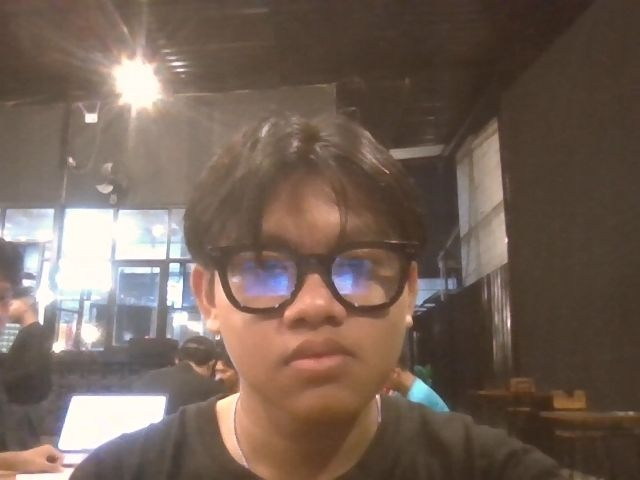

frame 7 -> 0 wajah


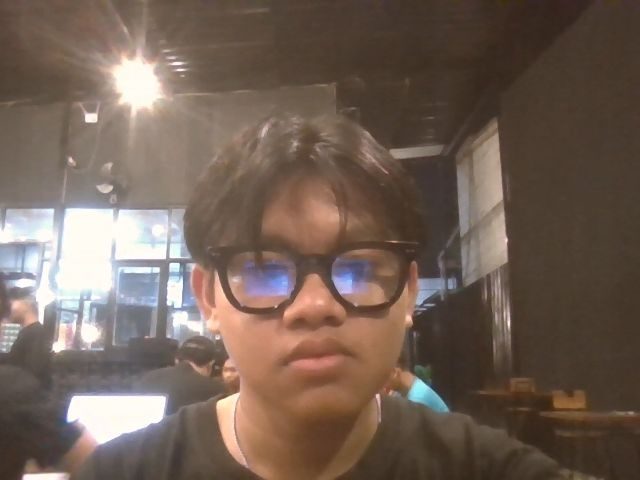

frame 8 -> 0 wajah


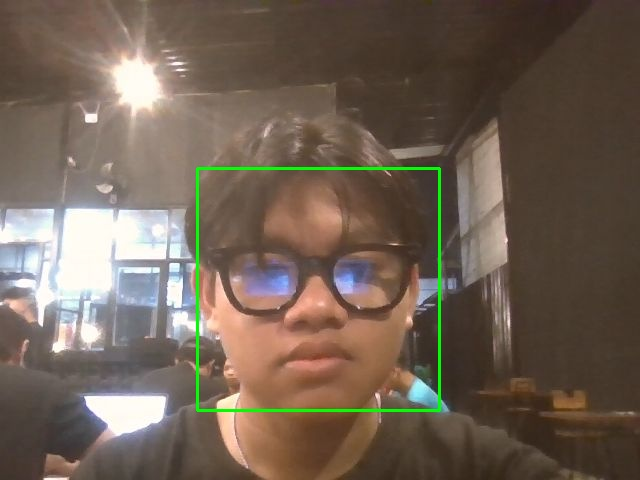

frame 9 -> 1 wajah


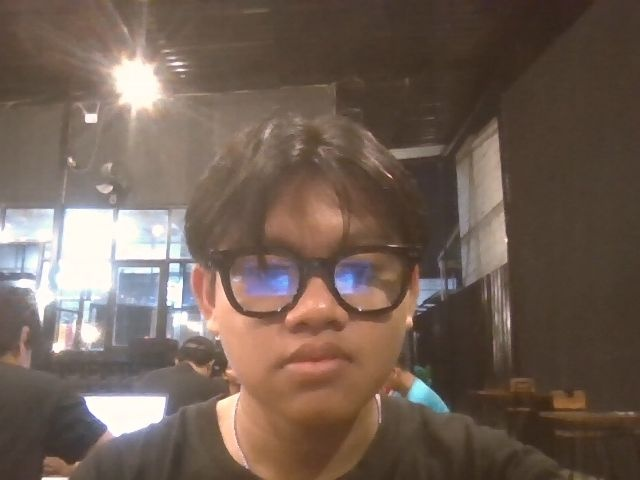

frame 10 -> 0 wajah


In [30]:
try:
    from google.colab.output import eval_js
    from IPython.display import display as ipy_display, Javascript, Image as IPyImage
    from base64 import b64decode
    import PIL.Image
    import io
    import time

    COLAB_OK = True
except ImportError:
    COLAB_OK = False
    print('Sel ini hanya untuk Google Colab (butuh akses kamera browser).')

if COLAB_OK:
    JS_KAMERA = """
    var video;
    var div = null;
    var stream;

    function takeSnapshots(quality) {
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      return canvas.toDataURL('image/jpeg', quality);
    }

    async function initCamera() {
      if (div !== null) { div.remove(); div = null; }
      div = document.createElement('div');
      document.body.appendChild(div);
      video = document.createElement('video');
      video.style.display = 'block';
      div.appendChild(video);
      try {
        stream = await navigator.mediaDevices.getUserMedia({video: true});
        video.srcObject = stream;
        await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        return "OK";
      } catch (err) {
        return "ERROR: " + err.name + " - " + err.message;
      }
    }

    async function grabFrame(quality) {
      return takeSnapshots(quality);
    }
    """

    def baca_frame(kualitas=0.8):
        data = eval_js("grabFrame({})".format(kualitas))
        biner = b64decode(data.split(',')[1])
        return cv.cvtColor(np.array(PIL.Image.open(io.BytesIO(biner))), cv.COLOR_RGB2BGR)

    ipy_display(Javascript(JS_KAMERA))
    status_kamera = eval_js('initCamera()')

    if status_kamera == "OK":
        for i in range(10):                      # 10 frame, lalu berhenti
            frame = baca_frame()
            abu = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            roi_wajah = cascade_wajah.detectMultiScale(abu, scaleFactor=1.1, minNeighbors=5)

            hasil = frame.copy()
            for (x, y, w, h) in roi_wajah:
                cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

            ipy_display(IPyImage(data=cv.imencode('.jpg', hasil)[1].tobytes()))
            print('frame', i + 1, '->', len(roi_wajah), 'wajah')
            time.sleep(0.3)

        eval_js('stream.getTracks().forEach(t => t.stop())')     # matikan kamera
    else:
        print("Kamera gagal dibuka:", status_kamera)
        print("Silakan periksa izin kamera pada browser Anda (klik ikon gembok di sebelah kiri URL) lalu jalankan ulang sel ini.")

## Soal 13 - Blurring pada Wajah yang Terdeteksi

Setelah wajah ditemukan, ROI wajah diganti dengan versi yang sudah di-`medianBlur`.
Median blur dipilih karena menghilangkan detail tanpa menimbulkan efek kotak seperti
blur rata-rata. Ukuran kernel harus **ganjil**; di sini dipakai sekitar sepertiga lebar
wajah supaya tingkat kekaburan menyesuaikan ukuran wajah.

wajah (42, 80) ukuran 229x229 -> medianBlur kernel 77


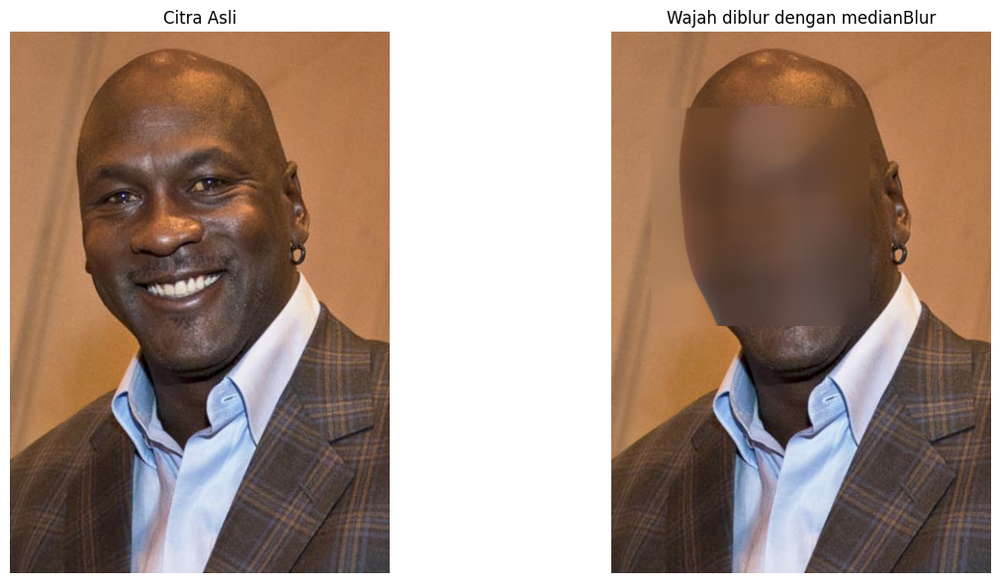

In [31]:
img = cv.imread(path('mjordan.jpg', 'facedet'))
abu = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

hasil = img.copy()
for (x, y, w, h) in cascade_wajah.detectMultiScale(abu, scaleFactor=1.1, minNeighbors=5):
    k = max(3, (w // 3) | 1)                       # ukuran kernel ganjil
    roi_wajah = hasil[y:y + h, x:x + w]
    hasil[y:y + h, x:x + w] = cv.medianBlur(roi_wajah, k)
    print('wajah ({}, {}) ukuran {}x{} -> medianBlur kernel {}'.format(x, y, w, h, k))

bandingkan(img, hasil, 'Citra Asli', 'Wajah diblur dengan medianBlur')

---
## Soal 14 - Mengolah Gambar KTM

### 14a & 14b - Menampilkan KTM dan Memotong Foto

Citra: `ktm_saya.jpg` (foto KTM masing-masing). Bagian foto dipotong berdasarkan
koordinat yang dinyatakan dalam **pecahan** (0-1) dari lebar dan tinggi citra, supaya
mudah disesuaikan tanpa mengubah rumus.

Nilai pecahan di bawah mengikuti tata letak KTM Polinema (foto di kiri bawah). Setelah
sel dijalankan, lihat kotak hijau pada KTM: kalau belum tepat menutup foto, ubah
`x1`, `x2`, `y1`, `y2` lalu jalankan ulang sel. Garis bantu pada gambar adalah grid
10% supaya lebih mudah memperkirakan koordinat.

file: /content/drive/MyDrive/PCVK/Images/ktm_saya.jpeg | ada: True


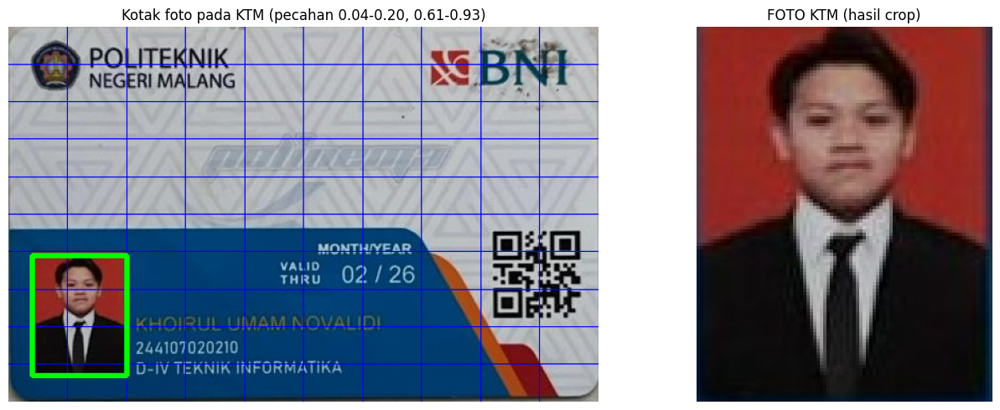

foto hasil crop disimpan sebagai: /content/drive/MyDrive/PCVK/Images/foto_ktm.jpg


In [42]:
BERKAS_KTM = path('ktm_saya.jpeg')
print('file:', BERKAS_KTM, '| ada:', os.path.exists(BERKAS_KTM))

if os.path.exists(BERKAS_KTM):
    ktm = cv.imread(BERKAS_KTM)
    tinggi, lebar = ktm.shape[:2]

    # koordinat kotak foto (pecahan dari lebar/tinggi citra) - sesuaikan bila perlu
    # nilai default mengikuti tata letak KTM Polinema: foto di kiri bawah, mulai 5% dari kiri
    x1, x2 = int(0.04 * lebar), int(0.20 * lebar)
    y1, y2 = int(0.61 * tinggi), int(0.93 * tinggi)

    penanda = ktm.copy()

    # garis bantu grid tiap 10% untuk memperkirakan koordinat
    for p in np.arange(0.1, 1.0, 0.1):
        cv.line(penanda, (int(p * lebar), 0), (int(p * lebar), tinggi), (255, 0, 0), 1)
        cv.line(penanda, (0, int(p * tinggi)), (lebar, int(p * tinggi)), (255, 0, 0), 1)

    cv.rectangle(penanda, (x1, y1), (x2, y2), (0, 255, 0), 3)

    foto = ktm[y1:y2, x1:x2].copy()
    bandingkan(penanda, foto, 'Kotak foto pada KTM (pecahan {:.2f}-{:.2f}, {:.2f}-{:.2f})'
               .format(x1 / lebar, x2 / lebar, y1 / tinggi, y2 / tinggi),
               'FOTO KTM (hasil crop)', figsize=(14, 5))

    cv.imwrite(path('foto_ktm.jpg'), foto)
    print('foto hasil crop disimpan sebagai:', path('foto_ktm.jpg'))
else:
    print('Letakkan foto KTM di', BERKAS_KTM, 'lalu jalankan ulang sel ini.')

### 14c - Deteksi Objek KTM dengan Feature Matching

Citra: `ktm_barang.jpg` (KTM bersama barang lain). KTM dicari memakai konsep feature
matching: keypoint SIFT dideteksi pada KTM dan pada citra adegan, deskriptor dicocokkan
dengan ratio test, lalu lokasi KTM dihitung sebagai kotak pembatas (bounding box) dari
keypoint yang lolos. Kalau tersedia minimal 4 titik, homografi dipakai supaya kotaknya
mengikuti kemiringan KTM pada foto.

keypoint KTM: 1137 | keypoint adegan: 1147
pencocokan lolos ratio test: 1124
KTM ditemukan di sekitar (0, 0) ukuran 556x354


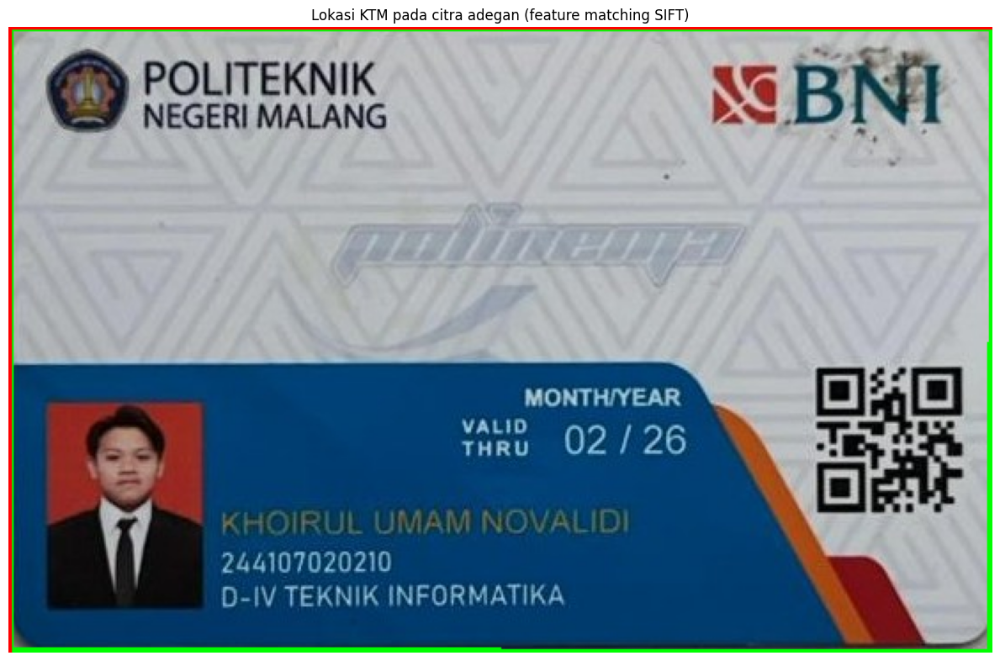

In [44]:
BERKAS_ADEGAN = path('ktm_barang.jpeg')

if os.path.exists(BERKAS_KTM) and os.path.exists(BERKAS_ADEGAN):
    ktm_abu   = cv.imread(BERKAS_KTM, 0)
    adegan    = cv.imread(BERKAS_ADEGAN)
    adegan_abu = cv.cvtColor(adegan, cv.COLOR_BGR2GRAY)

    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(ktm_abu, None)
    kp2, des2 = sift.detectAndCompute(adegan_abu, None)

    bf = cv.BFMatcher()
    pasangan = bf.knnMatch(des1, des2, k=2)
    baik = [m for m, n in pasangan if m.distance < 0.75 * n.distance]
    print('keypoint KTM:', len(kp1), '| keypoint adegan:', len(kp2))
    print('pencocokan lolos ratio test:', len(baik))

    hasil = adegan.copy()
    if len(baik) >= 4:
        titik_ktm    = np.float32([kp1[m.queryIdx].pt for m in baik]).reshape(-1, 1, 2)
        titik_adegan = np.float32([kp2[m.trainIdx].pt for m in baik]).reshape(-1, 1, 2)

        M, mask = cv.findHomography(titik_ktm, titik_adegan, cv.RANSAC, 5.0)
        h, w = ktm_abu.shape
        sudut = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        tujuan = cv.perspectiveTransform(sudut, M)
        cv.polylines(hasil, [np.int32(tujuan)], True, (0, 255, 0), 4)

        # kotak lurus sebagai pembanding
        x, y, w_box, h_box = cv.boundingRect(np.int32(tujuan))
        cv.rectangle(hasil, (x, y), (x + w_box, y + h_box), (0, 0, 255), 2)
        print('KTM ditemukan di sekitar ({}, {}) ukuran {}x{}'.format(x, y, w_box, h_box))
    else:
        print('Pencocokan terlalu sedikit, KTM tidak dapat dilokalisasi.')

    display(hasil, judul='Lokasi KTM pada citra adegan (feature matching SIFT)')
else:
    print('Letakkan', BERKAS_KTM, 'dan', BERKAS_ADEGAN, 'lalu jalankan ulang sel ini.')

---
# D3. Tugas Pengayaan - Pengenalan Karakter KTM dengan CNN

Bagian ini mengenali karakter (angka 0-9 dan huruf A-Z) pada KTM memakai CNN.
Datanya disiapkan manual: setiap karakter pada KTM di-crop dengan image editor,
lalu disimpan satu folder per kelas:

```
dataset/training/
|- 0/  |- 1/  |- ...  |- 9/      (gambar per karakter)
dataset/testing/
|- plat01/  (satu folder berisi karakter berurutan dari kiri ke kanan)
```

Sel-sel di bawah berhenti dengan pesan (bukan error) kalau folder dataset belum ada.

In [49]:
import random
import pickle

try:
    from tqdm import tqdm
except ImportError:                     # tqdm hanya untuk progress bar, bukan wajib
    def tqdm(data, desc=None):
        return data

DATADIR = os.path.join(BASE_DIR, 'dataset', 'training')
width, height = 100, 100

if not os.path.isdir(DATADIR):
    print('Dataset belum tersedia di', DATADIR)
    print('Letakkan gambar karakter per kelas (0-9, A-Z) di folder tersebut, lalu jalankan ulang.')
else:
    dirs = sorted(os.listdir(DATADIR))          # daftar nama kelas
    training_data = []

    for char_name in dirs:
        folder = os.path.join(DATADIR, char_name)
        class_number = dirs.index(char_name)
        for img in tqdm(os.listdir(folder), desc=char_name):
            try:
                img_array = cv.imread(os.path.join(folder, img), cv.IMREAD_GRAYSCALE)
                new_array = cv.resize(img_array, (width, height))
                training_data.append([new_array, class_number])
            except Exception:
                pass

    random.shuffle(training_data)

    X, Y = [], []
    for feature, label in training_data:
        X.append(feature)
        Y.append(label)

    X = np.array(X).reshape(-1, width, height, 1)
    Y = np.array(Y)

    pickle.dump(X, open('X.pickle', 'wb'))
    pickle.dump(Y, open('Y.pickle', 'wb'))
    pickle.dump(dirs, open('kelas.pickle', 'wb'))

    print('jumlah data :', len(training_data))
    print('jumlah kelas:', len(dirs), dirs)

V: 100%|██████████| 40/40 [00:15<00:00,  2.53it/s]

jumlah data : 1020
jumlah kelas: 20 ['0', '1', '2', '4', '7', 'A', 'D', 'E', 'F', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'R', 'T', 'U', 'V']


### Training Model CNN

Arsitektur CNN yang dipakai: ZeroPadding -> Conv2D(16) -> MaxPooling -> Conv2D(32) ->
Conv2D(32) -> MaxPooling -> Conv2D(64) -> Flatten -> Dense(256) -> Dense(64) -> Softmax.
Ekstraksi fitur dilakukan otomatis oleh lapisan konvolusi, berbeda dari neural network
biasa yang fiturnya harus dicari manual.

In [50]:
if not os.path.exists('X.pickle'):
    print('X.pickle belum ada - jalankan sel persiapan dataset lebih dulu.')
else:
    from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D)
    from keras.models import Model
    from keras.optimizers import Adam
    from keras.utils import to_categorical

    X = pickle.load(open('X.pickle', 'rb'))
    Y = pickle.load(open('Y.pickle', 'rb'))

    Y = to_categorical(Y)
    X = X / 255.0
    jumlah_kelas = Y.shape[1]

    inputs     = Input(shape=(width, height, 1))
    conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
    conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
    conv_layer = MaxPooling2D((2, 2))(conv_layer)
    conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
    conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
    conv_layer = MaxPooling2D((2, 2))(conv_layer)
    conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

    flaten    = Flatten()(conv_layer)
    fc_layer  = Dense(256, activation='relu')(flaten)
    fc_layer  = Dense(64, activation='relu')(fc_layer)
    outputs   = Dense(jumlah_kelas, activation='softmax')(fc_layer)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    model.summary()

    riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
    model.save('anpr.keras')

    print('akurasi training :', riwayat.history['accuracy'][-1])
    print('akurasi validasi :', riwayat.history['val_accuracy'][-1])

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 104, 104, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     7,225,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,276,148 (27.76 MB)

 Trainable params: 7,276,148 (27.76 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 19s 636ms/step - accuracy: 0.4510 - loss: 2.2771 - val_accuracy: 0.7206 - val_loss: 1.1889
Epoch 2/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 618ms/step - accuracy: 0.8517 - loss: 0.6139 - val_accuracy: 0.9216 - val_loss: 0.3022
Epoch 3/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 17s 645ms/step - accuracy: 0.9559 - loss: 0.1560 - val_accuracy: 0.9706 - val_loss: 0.0890
Epoch 4/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 20s 614ms/step - accuracy: 0.9743 - loss: 0.0734 - val_accuracy: 0.9853 - val_loss: 0.0690
Epoch 5/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 612ms/step - accuracy: 0.9914 - loss: 0.0411 - val_accuracy: 0.9755 - val_loss: 0.0603
Epoch 6/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 633ms/step - accuracy: 0.9914 - loss: 0.0290 - val_accuracy: 0.9804 - val_loss: 0.0534
Epoch 7/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 635ms/step - accuracy: 0.9939 - loss: 0.0205 - val_accuracy: 0.9657 - val_loss: 0.0832
Epoch 8/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 17s 640ms/step - accuracy: 0.9902 - loss: 0.0246 - val_accu

### Testing Model: Membaca Karakter pada KTM

Setiap folder di `dataset/testing` berisi karakter sebuah KTM yang sudah di-crop
berurutan dari kiri ke kanan. Model memprediksi satu karakter per gambar, lalu hasilnya
digabung menjadi satu string.

In [51]:
data_dir_testing = os.path.join(BASE_DIR, 'dataset', 'testing')

if not os.path.exists('anpr.keras') or not os.path.isdir(data_dir_testing):
    print('Model anpr.keras atau folder testing belum tersedia:', data_dir_testing)
else:
    import tensorflow as tf

    model = tf.keras.models.load_model('anpr.keras')
    dirs = pickle.load(open('kelas.pickle', 'rb'))     # urutan kelas saat training

    for car in sorted(os.listdir(data_dir_testing)):
        temp = ''
        folder = os.path.join(data_dir_testing, car)
        for char_img in sorted(os.listdir(folder)):
            img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            new_array = new_array.reshape(-1, width, height, 1) / 255.0
            prediction = model.predict(new_array, verbose=0)
            temp += dirs[np.argmax(prediction[0])]
        print('folder name: {} no: {}'.format(car, temp))

folder name: ktm01 no: 244107020210KHOIRULUMAMNOVALIDIDIVTEKNIKINFORMATIKA
